In [1]:
import numpy as np
import pylab as plt
import scipy as sp
import pickle
import imageio
import os
from scipy.interpolate import interp1d
from scipy.special import gamma
from scipy.integrate import odeint

In [2]:
#Constants
BohrMagneton=9.7e-24
Boltzmann=1.38e-23
amu=1.6e-27

In [3]:
#Defaults 
BohrRad=5.3e-11
R0=0.025
rho_ref=1e18
rho0=1e18
v0=70
sigma_ref=4.52e-20
sigma0=4.4e-16
N0=4
eta0=12
T0=10
phi0=1e8
B0=0.7
T0=0.1
M=3
v0=np.sqrt(T0*Boltzmann/(M*amu))

In [5]:
#Various useful series
theta=np.linspace(0,6.3,100)
XC=np.cos(theta)
SC=np.sin(theta)
XX,YY=np.meshgrid(np.linspace(-1,1,100),np.linspace(-1,1,100))
ZZ=XX+complex(0,1)*YY

In [6]:
def alpha(N):
    return np.sin((1/2+1/N)*np.pi)/(2*np.pi*(1/4-1/N**2))

def etaT( N,MaxB,T):
    return alpha(N)*BohrMagneton/(Boltzmann*T)

def equilR(eta,N,phi,sigma,v):
    return 2/(np.pi*gamma((N+2)/(N-2)))*eta**(2/(N-2))*phi*sigma/v

def Potential(rp,eta,N):
    return eta*rp**(N/2-1)

def DensityFixedR(rp,eta,N,phi,v,R):
    return phi*eta**(4/(N-2))/(np.pi*v*sp.special.gamma((N+2)/(N-2))*R**2)*np.exp(-eta*rp**(N/2-1))

def EKin(rp,eta,N,phi,v,R):
    return 3/2*DensityFixedR(rp,eta,N,phi,v,R)

def EPot(rp,eta,N,phi,v,R):
    return DensityFixedR(rp,eta,N,phi,v,R)*Potential(rp,eta,N)

def etacut(rp,eta,N):
    return((1-(rp)**(N/2-1))*eta)

def gam(eta,N,phi,sigma,v,R):
    return 4/(np.pi*gamma((N+2)/(N-2)))*eta**(+2/(N-2))*phi*sigma/(v*R)

In [7]:
#Load gamma

f=open("./GammaFile_T1K_rho1e18.pkl",'rb')
LogGammaE,LogGammaN=pickle.load(f)
f.close()
GammaN=lambda eta: np.exp(LogGammaN(eta))
GammaE=lambda eta: np.exp(LogGammaE(eta))

In [8]:
#Loss functions

def TotalLosses(eta,N,phi,v,R,bins=1000):
    rps=np.linspace(0,1,bins)
    particlelosses=sum(GammaN(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,phi,v,R)/rho_ref)*(sigma0/sigma_ref)*DensityFixedR(rps,eta,N,phi,v,R)*(2*np.pi*rps)*R**2/bins)
    kinlosses=sum(EKin(rps,eta,N,phi,v,R)*GammaE(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,phi,v,R)/rho_ref)*(sigma0/sigma_ref)* (2.*np.pi*rps)*R**2/bins)
    potlosses=sum(EPot(rps,eta,N,phi,v,R)*GammaN(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,phi,v,R)/rho_ref)*(sigma0/sigma_ref)* (2.*np.pi*rps)*R**2/bins)
    energylosses=kinlosses+potlosses
    return(np.array([particlelosses,kinlosses,potlosses,energylosses]))

def TotalCounts(eta,N,phi,v,R,bins=1000):
    rps=np.linspace(0,1,bins)
    particles=sum(DensityFixedR(rps,eta,N,phi,v,R)*(2*np.pi*rps)*R**2/bins)
    kin=sum(EKin(rps,eta,N,phi,v,R)* (2.*np.pi*rps)*R**2/bins)
    pot=sum(EPot(rps,eta,N,phi,v,R)* (2.*np.pi*rps)*R**2/bins)
    energy=kin+pot
    return(np.array([particles,kin,pot,energy]))

def FracLosses(eta,N,phi,v,R,bins=1000):
    return(TotalLosses(eta,N,phi,v,R,bins)/TotalCounts(eta,N,phi,v,R,bins))

In [9]:

def GetLnGradients_Eta_N_R(p,z):
    T=np.exp(p[0])
    phi=np.exp(p[1])
    Losses=FracLosses(fEta(z),fN(z),phi,v0,fR(z))*np.sqrt(T)/v0
    return(-(Losses[3]-Losses[0]),-Losses[0])

def GetLnGradients_B_N_R(p,z):
    T=np.exp(p[0])
    phi=np.exp(p[1])
    eta=fB(z)*BohrMagneton*alpha(fN(z))/(T*Boltzmann)
    Losses=FracLosses(eta,fN(z),phi,v0,fR(z))*np.sqrt(T)/v0
    return(-(Losses[3]-Losses[0]),-Losses[0])





In [10]:
#Set up three functions, fN, fR, fEta, and two initial conditions phi0, T0

v0=70
T0=0.2
phi0=5e17
z0=0


AllZs=[]
AllTs=[]
AllPhis=[]

AllRs=[]
AllNs=[]
AllEtas=[]
AllVs=[]



eta0=8.5

Ls=np.array([1.5])
etas=[-1]
Ns=[4]
Rs=[0.05]
Bs=[0.5]


for Li in range(0,len(Ls)):
    L=Ls[Li]
    eta0=etas[Li]
    N0=Ns[Li]
    R0=Rs[Li]
    zs=np.linspace(0,L,150)

    
    R0s=list(np.linspace(0.06,0.03,150))
    fN=interp1d(zs,list((np.ones_like(zs))*N0),bounds_error=False,fill_value='extrapolate')
    fR=interp1d(zs,R0s,bounds_error=False,fill_value='extrapolate')    
    fEta=interp1d(zs,list((np.ones_like(zs))*eta0),bounds_error=False,fill_value='extrapolate')
    fB=interp1d(zs,list((np.ones_like(zs))*B0),bounds_error=False,fill_value='extrapolate')

    GetLnGradients=GetLnGradients_B_N_R

    sol=odeint(GetLnGradients,[np.log(T0),np.log(phi0)],zs)
    AllPhis+=list(np.exp(sol[:,1]))
    AllTs+=list(np.exp(sol[:,0]))

    AllVs+=list(v0*np.ones_like(zs))
    
    AllNs+=list((np.ones_like(zs))*N0)
    AllEtas+=list((np.ones_like(zs))*eta0)
    AllRs+=list(np.ones_like(zs)*R0)
    AllZs+=list(z0+zs)
    z0=AllZs[-1]
    
    T0=AllTs[-1]*3
    phi0=AllPhis[-1]
    v0=AllVs[-1]*0.6

/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_66785/4256318699.py:11: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,1.1)


(0.09069385551118807, 1.1)

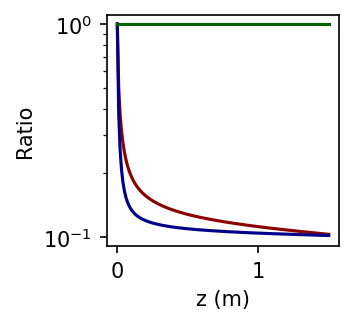

In [11]:
plt.figure(figsize=(2,2),dpi=150)
plt.plot(AllZs,np.array(AllTs)/AllTs[0],label=r'$T/T_0$',color='DarkRed')
plt.plot(AllZs,np.array(AllPhis/AllPhis[0]),label=r'$j/j_0$',color='DarkBlue')
plt.plot(AllZs,np.array(AllVs/AllVs[0]),label=r'$v/v_0$',color='DarkGreen')
plt.semilogy()
#plt.legend(loc='upper right')
plt.xlabel("z (m)")
plt.ylabel("Ratio")
#plt.xlim(0,600)
#plt.plot([0,6],[1/60,1/60],'--',color='blue')
plt.ylim(0,1.1)
#plt.semilogy()
#plt.xlim(0,1)
#plt.semilogx()
#plt.title(r"$j_0=5\times10^{17}\mathrm {s}^{-1}, v_0 = 70 \mathrm{ms}^{-1}, T_0=0.1 \mathrm{K}$")

In [12]:
#Set up three functions, fN, fR, fEta, and two initial conditions phi0, T0





AllZs=[]
AllTs=[]
AllPhis=[]

AllRs=[]
AllNs=[]
AllEtas=[]
AllVs=[]

B0=0.5
R0=0.01
N0=8
eta0=5

Ls=np.array([2,2,2,2,2,2])
etas=[8.2,7.9,7.8,7.3,8.9,8.7]
Ns=[8,8,6,6,6,6]
Rs=[0.03,0.03,0.03,0.03,0.015,0.015]

AllRs=[]
AllNs=[]
AllEtas=[]
AllZs=[]

v0=70
T0=0.02
phi0=5e16
z0=0
for Li in range(0,len(Ls)):
    L=Ls[Li]
    eta0=etas[Li]
    N0=Ns[Li]
    R0=Rs[Li]
    zs=np.linspace(0,L,100)

    
    
    fN=interp1d(zs,list((np.ones_like(zs))*N0),bounds_error=False,fill_value='extrapolate')
    fR=interp1d(zs,list(np.ones_like(zs)*R0),bounds_error=False,fill_value='extrapolate')    
    fEta=interp1d(zs,list((np.ones_like(zs))*eta0),bounds_error=False,fill_value='extrapolate')
    
    GetLnGradients=GetLnGradients_Eta_N_R

    sol=odeint(GetLnGradients,[np.log(T0),np.log(phi0)],zs)
    AllPhis+=list(np.exp(sol[:,1]))
    AllTs+=list(np.exp(sol[:,0]))

    AllVs+=list(v0*np.ones_like(zs))
    
    AllNs+=list((np.ones_like(zs))*N0)
    AllEtas+=list((np.ones_like(zs))*eta0)
    AllRs+=list(np.ones_like(zs)*R0)
    AllZs+=list(z0+zs)
    z0=AllZs[-1]
    
    T0=AllTs[-1]*3
    phi0=AllPhis[-1]
    v0=AllVs[-1]*0.75
    #print(AllTs,AllPhis)

Text(0, 0.5, '$\\mathcal{M}$')

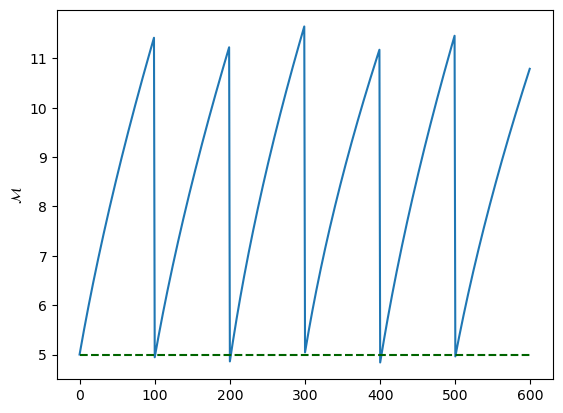

In [13]:
plt.plot(5*np.array(AllVs/AllVs[0])/np.sqrt(np.array(AllTs)/AllTs[0]))
plt.plot([0,600],[5,5],'--',color='DarkGreen')
plt.ylabel(r"$\mathcal{M}$")

In [17]:
#Set up three functions, fN, fR, fEta, and two initial conditions phi0, T0





AllZs=[]
AllTs=[]
AllPhis=[]

AllRs=[]
AllNs=[]
AllEtas=[]
AllVs=[]

B0=0.5
R0=0.01
N0=8
eta0=5

Ls=np.array([2,2,2,2,2,2])
etas=[11.4,11.3,12.7,12.5,12.4,12.1]
Ns=[8,8,6,6,6,6]
Rs=[0.01,0.01,0.0075,0.0075,0.0075,0.0075]

AllRs=[]
AllNs=[]
AllEtas=[]
AllZs=[]

v0=70
T0=0.02
phi0=5e16
z0=0
for Li in range(0,len(Ls)):
    L=Ls[Li]
    eta0=etas[Li]
    N0=Ns[Li]
    R0=Rs[Li]
    zs=np.linspace(0,L,100)

    
    
    fN=interp1d(zs,list((np.ones_like(zs))*N0),bounds_error=False,fill_value='extrapolate')
    fR=interp1d(zs,list(np.ones_like(zs)*R0),bounds_error=False,fill_value='extrapolate')    
    fEta=interp1d(zs,list((np.ones_like(zs))*eta0),bounds_error=False,fill_value='extrapolate')
    
    GetLnGradients=GetLnGradients_Eta_N_R

    sol=odeint(GetLnGradients,[np.log(T0),np.log(phi0)],zs)
    AllPhis+=list(np.exp(sol[:,1]))
    AllTs+=list(np.exp(sol[:,0]))

    AllVs+=list(v0*np.ones_like(zs))
    
    AllNs+=list((np.ones_like(zs))*N0)
    AllEtas+=list((np.ones_like(zs))*eta0)
    AllRs+=list(np.ones_like(zs)*R0)
    AllZs+=list(z0+zs)
    z0=AllZs[-1]
    
    T0=AllTs[-1]*3
    phi0=AllPhis[-1]
    v0=AllVs[-1]*0.75
    #print(AllTs,AllPhis)

[]

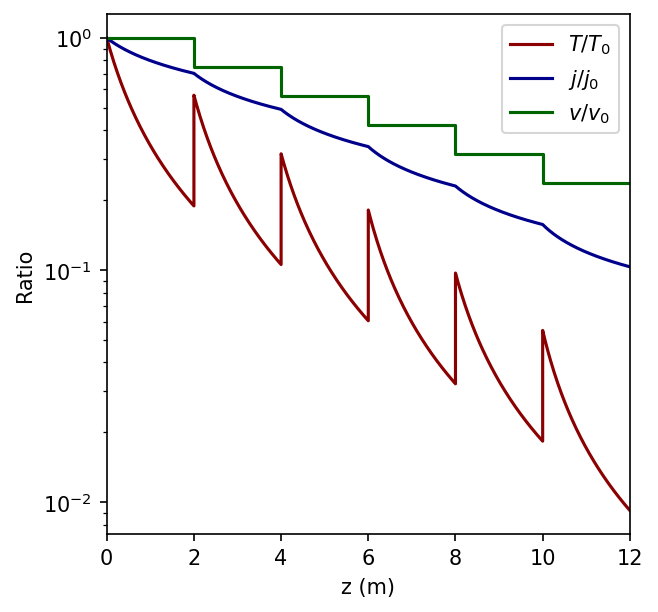

In [18]:

plt.figure(figsize=(4.5,4.5),dpi=150)
plt.plot(AllZs,np.array(AllTs)/AllTs[0],label=r'$T/T_0$',color='DarkRed')
plt.plot(AllZs,np.array(AllPhis/AllPhis[0]),label=r'$j/j_0$',color='DarkBlue')
plt.plot(AllZs,np.array(AllVs/AllVs[0]),label=r'$v/v_0$',color='DarkGreen')
plt.legend(loc='upper right')
plt.xlabel("z (m)")
plt.ylabel("Ratio")
#plt.xlim(0,600)
#plt.plot([0,12],[1/60,1/60],'--',color='dimgrey')
plt.xlim(0,12)
plt.semilogy()

<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\z'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\z'
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_66785/2034803288.py:11: SyntaxWarning: invalid escape sequence '\e'
  ax2.set_ylabel("$\eta$")
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_66785/2034803288.py:24: SyntaxWarning: invalid escape sequence '\z'
  ax5.set_ylabel("$\zeta$")


Text(0.5, 0, 'Distance (m)')

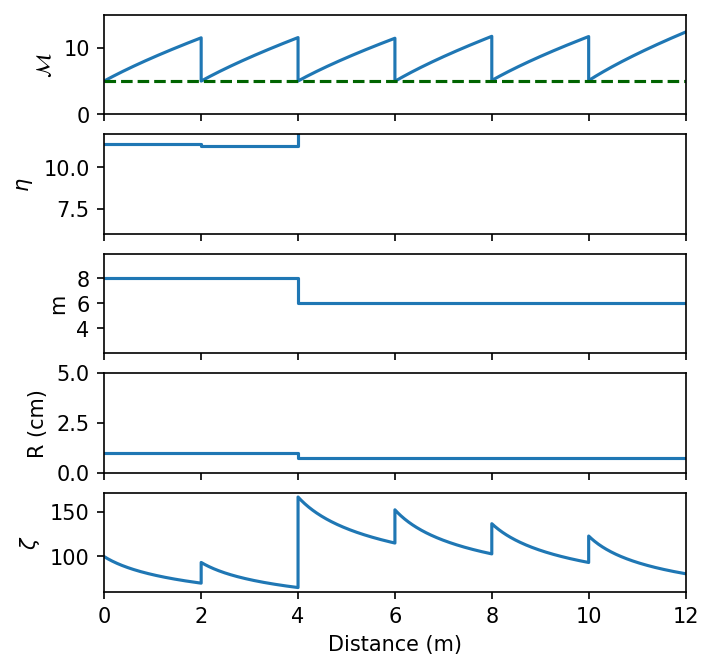

In [19]:
fig, (ax1, ax2,ax3,ax4,ax5) = plt.subplots(5, sharex=True,dpi=150,figsize=(5,5))
Boltzmann=8.6e-5
BohrMagneton=5.7e-5
ax1.plot(AllZs,5*np.array(AllVs/AllVs[0])/np.sqrt(np.array(AllTs)/AllTs[0]))
ax1.set_ylabel(r"$\mathcal{M}$")
ax1.plot([0,600],[5,5],'--',color='DarkGreen')

ax1.set_ylim([0,15])
ax1.set_xlim(0,12)
ax2.plot(AllZs,np.array(AllEtas))
ax2.set_ylabel("$\eta$")
ax2.set_ylim(6,12)
#ax2.set_yticks([1e-3,1e-1,10])
ax3.plot(AllZs,np.array(AllNs))
ax3.set_ylabel("m")
ax3.set_ylim(2,10)
ax3.set_yticks([4,6,8])
ax4.plot(AllZs,np.array(AllRs)*100)
ax4.set_ylim(0,5)
ax4.set_ylabel("R (cm)")
ax4.set_yticks([0,2.5,5])
ax5.plot(AllZs,gam(np.array(AllEtas),np.array(AllNs),np.array(AllPhis),sigma0,np.array(AllVs),np.array(AllRs)))
#ax5.set_ylim(11.5,14.5)
ax5.set_ylabel("$\zeta$")
#ax5.set_ylim([0,10])
#plt.plot([0,12],[1,1],'--',color='green')
ax5.set_xlabel("Distance (m)")

#ax2.set_ylim(1e-3,0.7)

<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\z'
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:24: SyntaxWarning: invalid escape sequence '\z'
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_98316/1529996714.py:11: SyntaxWarning: invalid escape sequence '\e'
  ax2.set_ylabel("$\eta$")
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_98316/1529996714.py:24: SyntaxWarning: invalid escape sequence '\z'
  ax5.set_ylabel("$\zeta$")


Text(0.5, 0, 'Distance (m)')

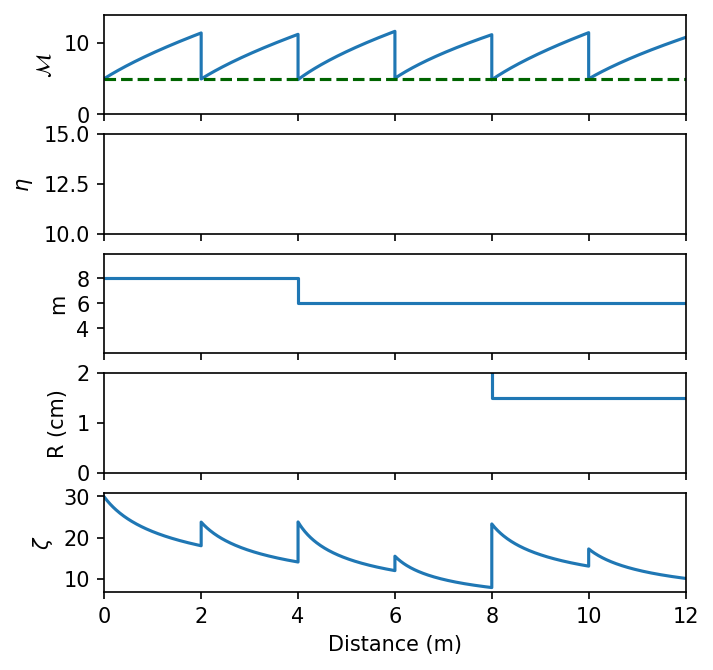

In [538]:

fig, (ax1, ax2,ax3,ax4,ax5) = plt.subplots(5, sharex=True,dpi=150,figsize=(5,5))
Boltzmann=8.6e-5
BohrMagneton=5.7e-5
ax1.plot(AllZs,5*np.array(AllVs/AllVs[0])/np.sqrt(np.array(AllTs)/AllTs[0]))
ax1.set_ylabel(r"$\mathcal{M}$")
ax1.plot([0,600],[5,5],'--',color='DarkGreen')

ax1.set_ylim([0,14])
ax1.set_xlim(0,12)
ax2.plot(AllZs,np.array(AllEtas))
ax2.set_ylabel("$\eta$")
ax2.set_ylim(10,15)
#ax2.set_yticks([1e-3,1e-1,10])
ax3.plot(AllZs,np.array(AllNs))
ax3.set_ylabel("m")
ax3.set_ylim(2,10)
ax3.set_yticks([4,6,8])
ax4.plot(AllZs,np.array(AllRs)*100)
ax4.set_ylim(0,2)
ax4.set_ylabel("R (cm)")
ax4.set_yticks([0,1,2])
ax5.plot(AllZs,gam(np.array(AllEtas),np.array(AllNs),np.array(AllPhis),sigma0,np.array(AllVs),np.array(AllRs)))
#ax5.set_ylim(11.5,14.5)
ax5.set_ylabel("$\zeta$")
#ax5.set_ylim([0,3])
#plt.plot([0,12],[1,1],'--',color='green')
ax5.set_xlabel("Distance (m)")

#ax2.set_ylim(1e-3,0.7)
